# MHW_biome_CESM2.ipynb
## Code to bring the biome and mhw intensity datasets together and do some analysis
### Brendan Myers
### 10/22/2026

In [1]:
%load_ext autoreload
%autoreload 2
import os
from glob import glob
from collections import OrderedDict
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import pop_tools 
from statistics import mean
from matplotlib import style
import colorcet as cc
from scipy import stats

import xmhw

ERROR 1: PROJ: proj_create_from_database: Open of /glade/work/brendanmy/conda-envs/bgc-env/share/proj failed
/glade/work/brendanmy/conda-envs/bgc-env/lib/python3.13/site-packages/pop_tools/__init__.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


In [2]:
da_biomes = xr.open_dataarray('/glade/u/home/brendanmy/INDEX-BGC/data/CESM2_biomes.nc').load()
ds_mhw = xr.open_dataset('/glade/u/home/brendanmy/INDEX-BGC/data/CESM2_intensity.nc').load()

In [3]:
da_biomes.max()

<xarray.DataArray ()> Size: 8B
array(13.)

In [4]:
ds_mhw

<xarray.Dataset> Size: 78MB
Dimensions:              (year: 64, nlat: 384, nlon: 320, month: 12)
Coordinates:
  * year                 (year) int64 512B 1958 1959 1960 ... 2019 2020 2021
  * month                (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
    TLAT                 (nlat, nlon) float64 983kB -79.22 -79.22 ... nan nan
    TLONG                (nlat, nlon) float64 983kB 320.6 321.7 ... nan nan
    z_t                  float32 4B 500.0
    z_t_150m             float32 4B 500.0
Dimensions without coordinates: nlat, nlon
Data variables:
    MHW_INTENSITY_year   (year, nlat, nlon) float32 31MB nan nan nan ... nan nan
    MCW_INTENSITY_year   (year, nlat, nlon) float32 31MB nan nan nan ... nan nan
    MHW_INTENSITY_month  (month, nlat, nlon) float32 6MB nan nan nan ... nan nan
    MCW_INTENSITY_month  (month, nlat, nlon) float32 6MB nan nan nan ... nan nan
    MHW_INTENSITY        (nlat, nlon) float32 492kB nan nan nan ... nan nan nan
    MCW_INTENSITY        (nlat, nlon) float32 492kB nan nan nan ... nan nan nan
Attributes:
    long_name:     Potential Temperature Anomoly
    units:         degC
    grid_loc:      3111
    cell_methods:  time: mean
    quantile:      0.9

In [5]:
ds = ds_mhw
ds['biomes'] = da_biomes

In [6]:
biomes = ['NH_ICE','NPac_SPSS','NAtl_SPSS',
          'NH_STSS','NH_STPS','IND_STPS','WPac_EQ',
          'EPac_EQ','Atl_EQ','SH_ICE','SH_SPSS','SH_STSS',
          'SH_STPS']

In [7]:
### First, get the pop grid information, so we have lon, lat
ds_grid = pop_tools.get_grid('POP_gx1v7')
lats = ds_grid.TLAT
lons = ds_grid.TLONG

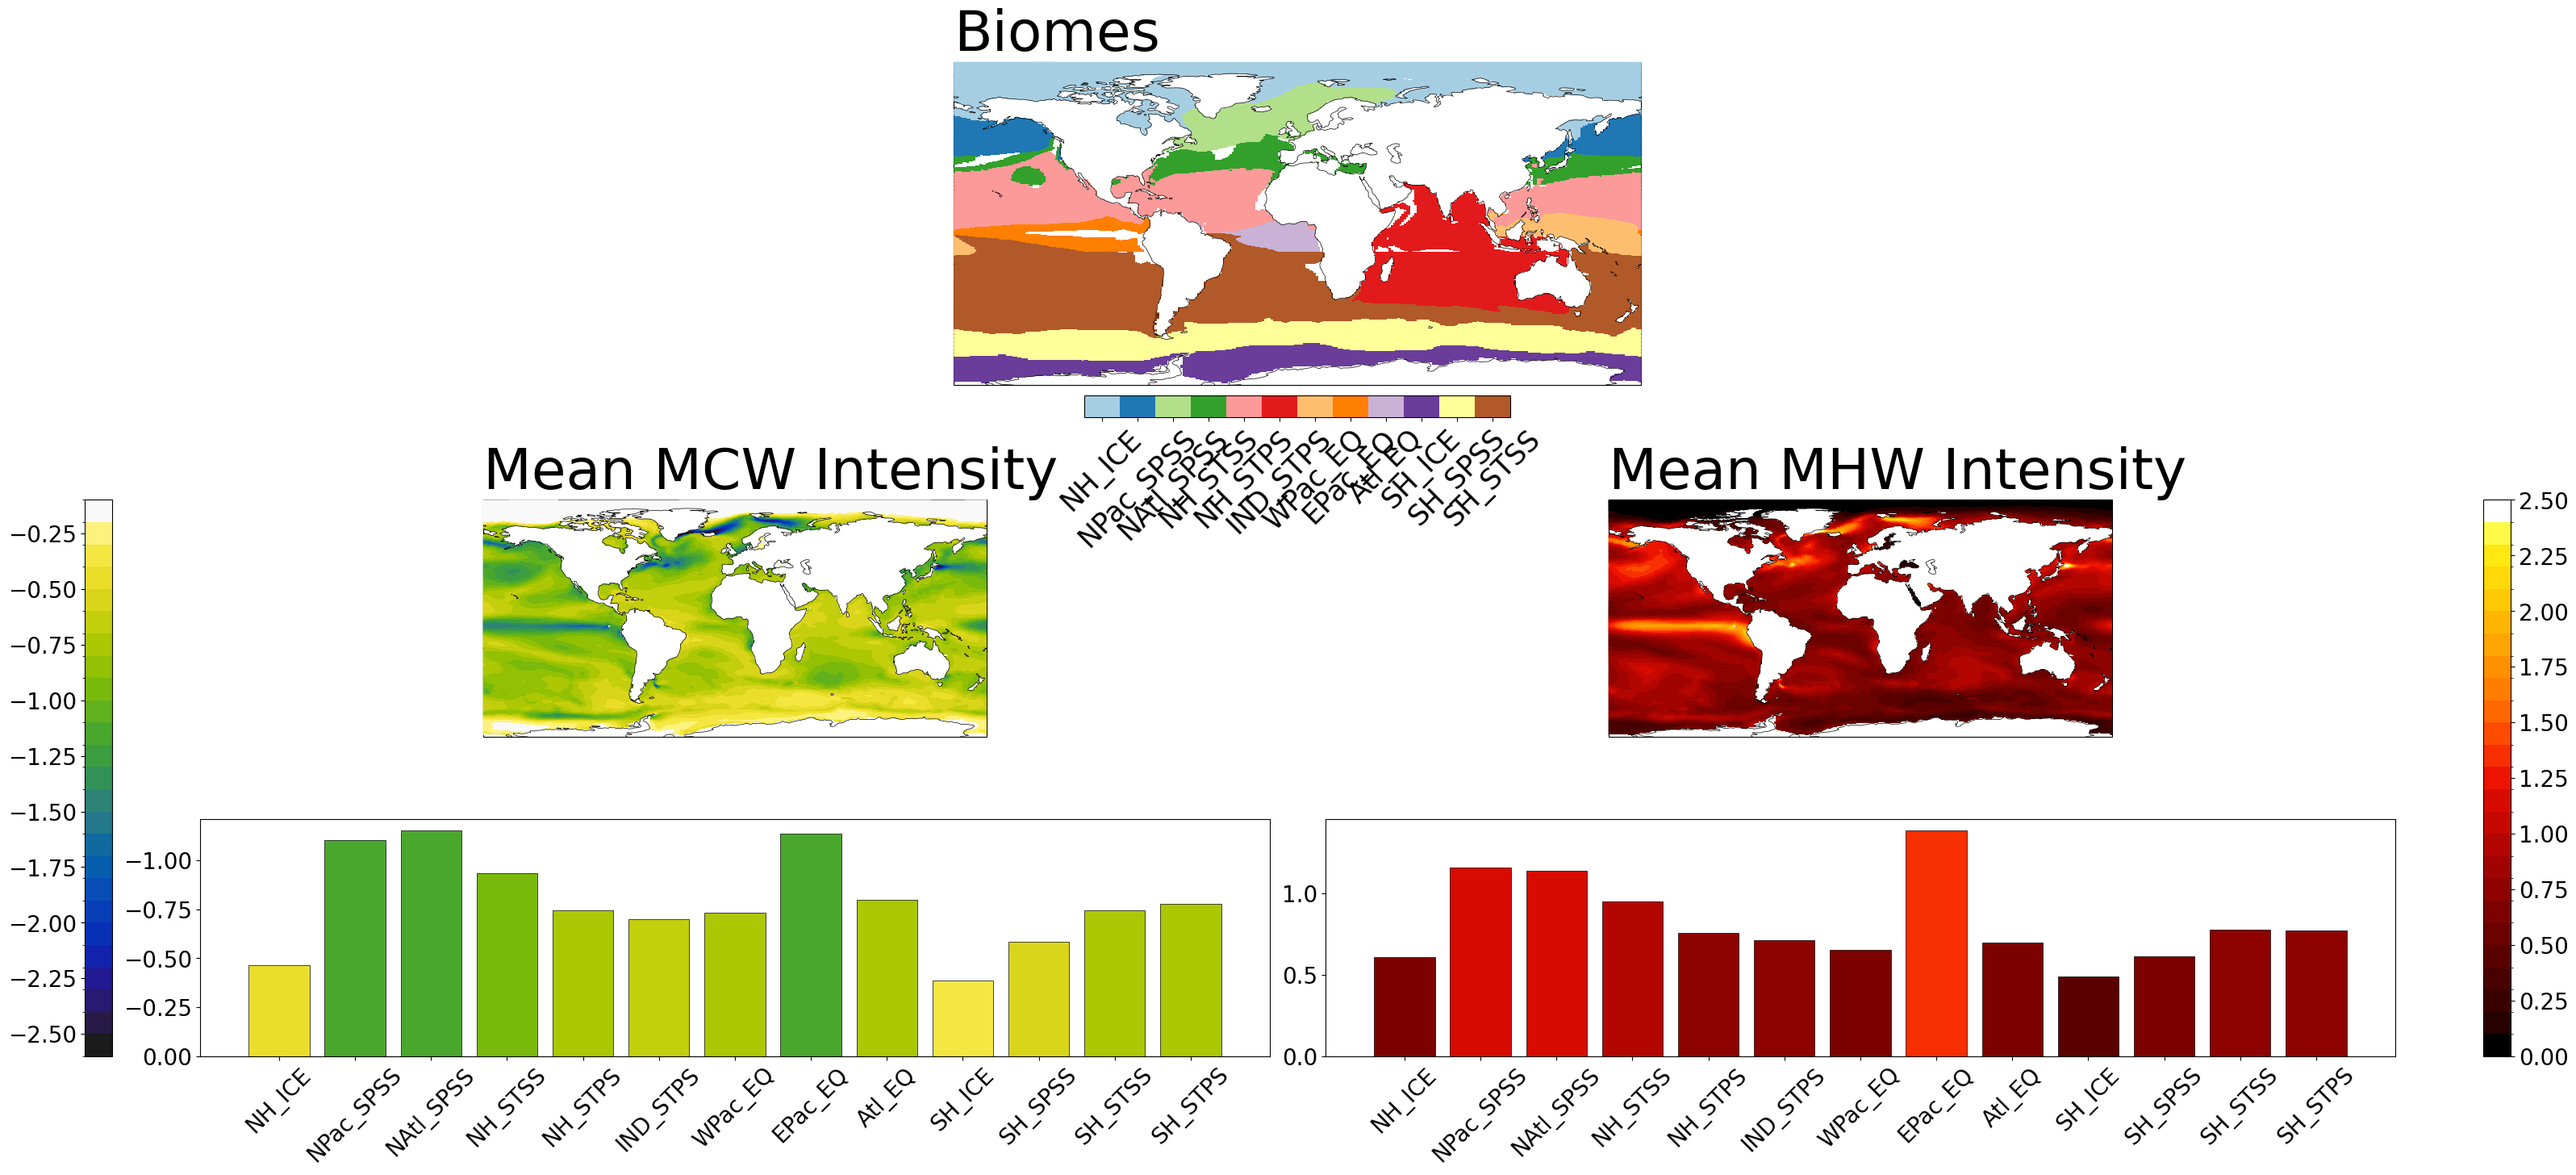

In [188]:
from matplotlib.gridspec import GridSpec
from matplotlib.colors import BoundaryNorm
import colorcet as cc
from matplotlib.colors import LinearSegmentedColormap
# sys.path.append(os.path.abspath('/glade/u/home/brendanmy/utils/python/'))
# import my_utils

fig = plt.figure(figsize=(42,16))
gs = GridSpec(3,8, figure=fig, hspace=0.3, height_ratios=[1.5,1,1], wspace=0.2, width_ratios=[0.5,1,1,1,1,1,1,0.5])

fs_title = 50
fs_suptitle = 75
fs_label = 25
fs_ticks = 20

ax1 = fig.add_subplot(gs[0,2:6], projection=ccrs.PlateCarree())
ax1.coastlines('110m',linewidth=0.5, zorder=100)
ax1.set_title('Biomes', fontsize=fs_title, loc='left')

pc1 = ax1.pcolormesh(lons, lats, ds.biomes.where(ds.biomes.values>0), cmap='Paired', alpha=1, zorder=20, transform=ccrs.PlateCarree())
cbar = fig.colorbar(pc1, ticks=np.arange(1.5,14,1), location='bottom', pad=0.03, fraction=0.06)
cbar.ax.set_xticklabels(biomes, rotation=45, fontsize=fs_label)


ax_hw = fig.add_subplot(gs[1,4:7], projection=ccrs.PlateCarree())
ticks_hw = np.arange(0,4,.25)
levels_hw = np.arange(0, 2.6, 0.1)
cmap_hw = cc.cm.fire
norm_hw = BoundaryNorm(levels_hw, ncolors=cmap_hw.N, clip=False)

ax_hw.coastlines('110m',linewidth=0.5, zorder=100)
ax_hw.set_title('Mean MHW Intensity', fontsize=fs_title, loc='left')
pc1 = ax_hw.pcolormesh(lons, lats, ds.MHW_INTENSITY, shading='nearest', cmap=cmap_hw, norm=norm_hw, rasterized=True, alpha=1, zorder=20, transform=ccrs.PlateCarree())

ax_hw_cbar = fig.add_subplot(gs[1:,7])
ax_hw_cbar.axis('off')
cbar_hw = fig.colorbar(pc1, ticks=ticks_hw, location='right', fraction=0.8, ax=ax_hw_cbar)
cbar_hw.ax.tick_params(labelsize=fs_ticks)


ax_cw = fig.add_subplot(gs[1,1:4], projection=ccrs.PlateCarree())
ticks_cw = np.arange(-3, 0, 0.25)
levels_cw = np.arange(-2.6, 0, 0.1)
cmap_cw = cc.cm.kbgyw
norm_cw = BoundaryNorm(levels_cw, ncolors=cmap_cw.N, clip=False)

ax_cw.coastlines('110m',linewidth=0.5, zorder=100)
ax_cw.set_title('Mean MCW Intensity', fontsize=fs_title, loc='left')
pc1 = ax_cw.pcolormesh(lons, lats, ds.MCW_INTENSITY, shading='nearest', cmap=cmap_cw, norm=norm_cw, rasterized=True, alpha=1, zorder=20, transform=ccrs.PlateCarree())

ax_cw_cbar = fig.add_subplot(gs[1:,0])
ax_cw_cbar.axis('off')
cbar_cw = fig.colorbar(pc1, ticks=ticks_cw, location='left', fraction=0.8, ax=ax_cw_cbar)
cbar_cw.ax.tick_params(labelsize=fs_ticks)

#Combined
regweights = np.cos(np.deg2rad(lats)).drop_attrs()

biome_mean_list = []
for i in np.arange(1,14,1):
    biome_mean_list.append(ds.where(ds.biomes==i).weighted(regweights).mean(['nlat','nlon'])[['MHW_INTENSITY','MCW_INTENSITY']].assign_coords({'biomes_ind':biomes[i-1]}))

ds_bar = xr.concat(biome_mean_list, dim='biome_ind')

ax_hw_b = fig.add_subplot(gs[2,4:7])
bar_colors = cmap_hw(norm_hw(ds_bar.MHW_INTENSITY.values))
ax_hw_b.bar(biomes, ds_bar.MHW_INTENSITY, label=biomes, color=bar_colors, edgecolor='black', linewidth=0.5)
ax_hw_b.tick_params(axis='both', which='major', labelsize=fs_ticks)
ax_hw_b.tick_params(axis='x', which='major', rotation=45)

ax_cw_b = fig.add_subplot(gs[2,1:4])
bar_colors = cmap_cw(norm_cw(ds_bar.MCW_INTENSITY.values))
ax_cw_b.bar(biomes, ds_bar.MCW_INTENSITY, label=biomes, color=bar_colors, edgecolor='black', linewidth=0.5)
ax_cw_b.invert_yaxis()
ax_cw_b.tick_params(axis='both', which='major', labelsize=fs_ticks)
ax_cw_b.tick_params(axis='x', which='major', rotation=45)


# ax_hw_b = fig.add_subplot(gs[1,3:], projection=ccrs.PlateCarree())
# ticks = np.arange(0,4,.25)
# levels = np.arange(0, 2.6, 0.1)
# cmap = cc.cm.fire
# norm = BoundaryNorm(levels, ncolors=cmap.N, clip=False)

# ax_hw_b.coastlines('110m',linewidth=0.5, zorder=100)
# ax_hw_b.set_title('Mean MHW Intensity Projected on Biomes', fontsize=12, loc='left')
# pc1 = ax_hw_b.pcolormesh(lons, lats, ds.MHW_INTENSITY, shading='nearest', cmap=cmap, norm=norm, rasterized=True, alpha=0.8, zorder=20, transform=ccrs.PlateCarree())
# cbar = fig.colorbar(pc1, ticks=ticks, pad=0.03)
# pc_b = ax_hw_b.pcolormesh(lons, lats, ds.biomes.where(ds.biomes.values>0), cmap='Paired', alpha=0.5, zorder=20, transform=ccrs.PlateCarree())


# ax_cw_b = fig.add_subplot(gs[1,:3], projection=ccrs.PlateCarree())
# ticks = np.arange(-3, 0, 0.25)
# levels = np.arange(-2.6, 0, 0.1)
# cmap = cc.cm.kbgyw
# norm = BoundaryNorm(levels, ncolors=cmap.N, clip=False)

# ax_cw_b.coastlines('110m',linewidth=0.5, zorder=100)
# ax_cw_b.set_title('Mean MCW Intensity Projected on Biomes', fontsize=12, loc='left')
# pc1 = ax_cw_b.pcolormesh(lons, lats, ds.MCW_INTENSITY, shading='nearest', cmap=cmap, norm=norm, rasterized=True, alpha=0.8, zorder=20, transform=ccrs.PlateCarree())
# cbar = fig.colorbar(pc1, ticks=ticks, pad=0.03)
# pc_b = ax_cw_b.pcolormesh(lons, lats, ds.biomes.where(ds.biomes.values>0), cmap='Paired', alpha=0.5, zorder=20, transform=ccrs.PlateCarree())
# # cntr1 = ds.biomes.where(ds.biomes.values>0).plot.contour(linewidths=0.5, cmap='Paired', transform=ccrs.PlateCarree(), ax=ax_cw_b)

In [149]:
#Combined
regweights = np.cos(np.deg2rad(lats)).drop_attrs()

biome_mean_list = []
for i in np.arange(1,14,1):
    print(i)
    biome_mean_list.append(ds.where(ds.biomes==i).weighted(regweights).mean(['nlat','nlon']).assign_coords({'biomes_ind':biomes[i-1]}))

ds_bar = xr.concat(biome_mean_list, dim='biome_ind')


1
2
3
4
5
6
7
8
9
10
11
12
13


In [150]:
ds_bar

<xarray.Dataset> Size: 17kB
Dimensions:              (biome_ind: 13, year: 64, month: 12)
Coordinates:
  * year                 (year) int64 512B 1958 1959 1960 ... 2019 2020 2021
  * month                (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
    z_t                  float32 4B 500.0
    z_t_150m             float32 4B 500.0
    biomes_ind           (biome_ind) <U9 468B 'NH_ICE' 'NPac_SPSS' ... 'SH_STPS'
Dimensions without coordinates: biome_ind
Data variables:
    MHW_INTENSITY_year   (biome_ind, year) float64 7kB 2.381 2.334 ... 1.741
    MCW_INTENSITY_year   (biome_ind, year) float64 7kB -1.165 -1.113 ... -1.626
    MHW_INTENSITY_month  (biome_ind, month) float64 1kB 0.147 0.08643 ... 0.8561
    MCW_INTENSITY_month  (biome_ind, month) float64 1kB -0.06715 ... -0.8263
    MHW_INTENSITY        (biome_ind) float64 104B 0.6104 1.158 ... 0.7778 0.7751
    MCW_INTENSITY        (biome_ind) float64 104B -0.4666 -1.104 ... -0.7768
Attributes:
    long_name:     Potential Temperature Anomoly
    units:         degC
    grid_loc:      3111
    cell_methods:  time: mean
    quantile:      0.9

In [165]:
ds.biomes.where(ds.biomes.values>0).biomes.min()

<xarray.DataArray 'biomes' ()> Size: 8B
array(0.)
Coordinates:
    z_t       float32 4B 500.0
    z_t_150m  float32 4B 500.0

In [28]:
print(ds)

<xarray.Dataset> Size: 79MB
Dimensions:              (year: 64, nlat: 384, nlon: 320, month: 12)
Coordinates:
  * year                 (year) int64 512B 1958 1959 1960 ... 2019 2020 2021
  * month                (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
    TLAT                 (nlat, nlon) float64 983kB -79.22 -79.22 ... nan nan
    TLONG                (nlat, nlon) float64 983kB 320.6 321.7 ... nan nan
    z_t                  float32 4B 500.0
    z_t_150m             float32 4B 500.0
Dimensions without coordinates: nlat, nlon
Data variables:
    MHW_INTENSITY_year   (year, nlat, nlon) float32 31MB nan nan nan ... nan nan
    MCW_INTENSITY_year   (year, nlat, nlon) float32 31MB nan nan nan ... nan nan
    MHW_INTENSITY_month  (month, nlat, nlon) float32 6MB nan nan nan ... nan nan
    MCW_INTENSITY_month  (month, nlat, nlon) float32 6MB nan nan nan ... nan nan
    MHW_INTENSITY        (nlat, nlon) float32 492kB nan nan nan ... nan nan nan
    MCW_INTENSITY        (nlat, nlon) floa